In [1]:
%load_ext autoreload
%autoreload 2
import emcee
import corner
import pickle
import time
from astropy.table import QTable
from astropy import units as u
from astropy import constants as const
import pandas as pd

from multiprocessing import Pool

import numpy as np
from matplotlib import pyplot as plt

from asymmetric_uncertainty_mod import a_u
from functions.statistics_functions import chi_squared
from functions.plotting import savefig, paper_plot
from functions.load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr

In [2]:
reflex_clean, variances = load_data_and_var()
reflex_clean.head()

,MCXC,OName,L500,Sub-Cat,RXC,Flux,e_Flux,ObsLum,LumCor,z_x,z_y,MSZ,E_MSZ,e_MSZ,L_err
1,J0003.8+0203,RXCJ0003.8+0203,0.846881,REFLEX,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924,0.0924,2.238774,0.282160,0.301448,0.136707
2,J0006.0-3443,RXCJ0006.0-3443,1.809494,REFLEX,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147,0.1147,4.001657,0.248869,0.226974,0.211627
3,J0011.3-2851,RXCJ0011.3-2851,1.086002,REFLEX,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620,0.0620,2.606369,0.182667,0.188038,0.086428
4,J0013.6-1930,RXCJ0013.6-1930,1.236332,REFLEX,RXCJ0013.6-1930,6.071,11.3,1.285,1.353,0.0940,0.0940,2.756623,0.233331,0.245311,0.124160
5,J0014.3-6604,RXCJ0014.3-6604,2.827248,REFLEX,RXCJ0014.3-6604,4.485,13.8,2.907,3.160,0.1599,0.1599,3.030337,0.328876,0.347930,0.313974


In [3]:
nfws_werr = generate_nfws_from_combined_dataset_werr(reflex_clean, variances)

In [4]:
nfws= [nfw for nfw in nfws_werr if nfw.energies.is_virialized_gaspari]
len(nfws)

111

In [5]:
max([n.z for n in nfws])

0.1926

In [6]:
test_nfw = nfws[0]

In [7]:
test_rs = np.logspace(-3, 0)*test_nfw.R500
test_rs

array([<asymmetric_uncertainty_mod.core.a_u object at 0x168e07ad0>,
      dtype=object)

Text(0, 0.5, 'v (km/s)')

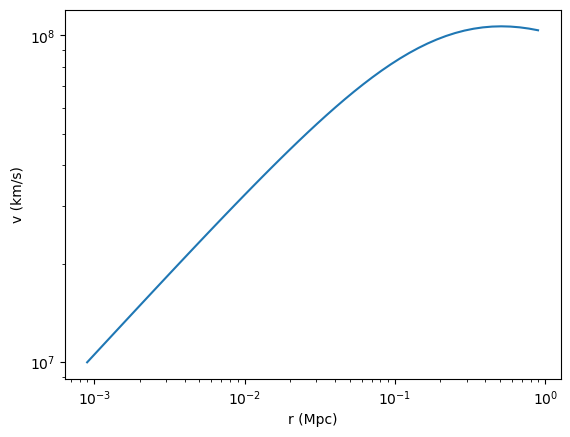

In [8]:
plt.loglog(test_rs, test_nfw.therm.velocity(test_rs))
plt.xlabel('r (Mpc)')
plt.ylabel('v (km/s)')

Text(0, 0.5, 'n_chi (1/Mpc3)')

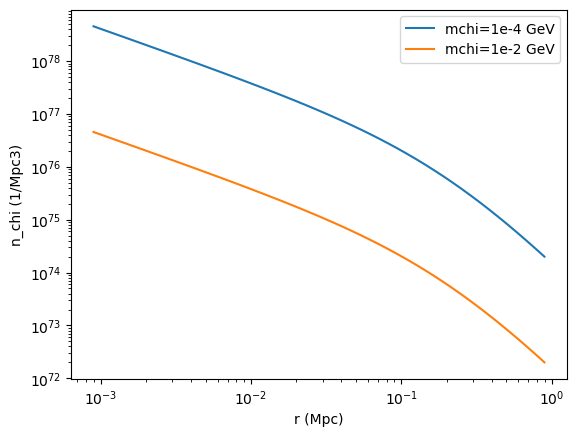

In [9]:
plt.loglog(test_rs, test_nfw.therm.dm_number_density(test_rs, 1e-4), label='mchi=1e-4 GeV')
plt.loglog(test_rs, test_nfw.therm.dm_number_density(test_rs, 1e-2), label='mchi=1e-2 GeV')
plt.legend()
plt.xlabel('r (Mpc)')
plt.ylabel('n_chi (1/Mpc3)')

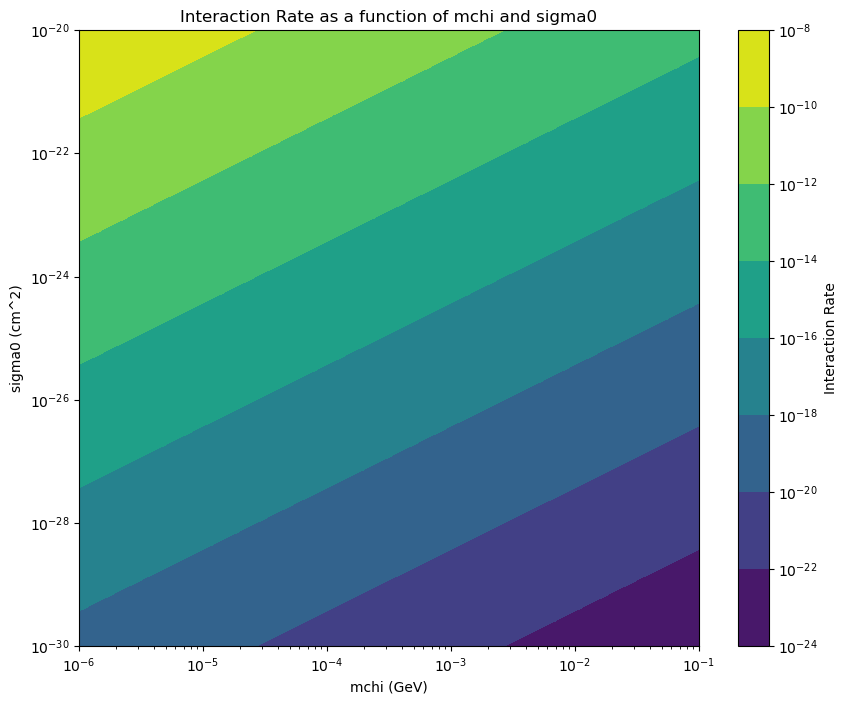

In [11]:
from matplotlib.colors import LogNorm

# Define the range of sigma0 and mchi values
sigma0_values = np.logspace(-30, -20, 50)  # Example range in cm^2
mchi_values = np.logspace(-6, -1, 50)       # Example range in GeV

# Create a meshgrid for sigma0 and mchi
sigma0_grid, mchi_grid = np.meshgrid(sigma0_values, mchi_values)

# Calculate the interaction rate for each combination of sigma0 and mchi
interaction_rate_grid = np.zeros_like(sigma0_grid)
for i in range(sigma0_grid.shape[0]):
    for j in range(sigma0_grid.shape[1]):
        sigma0 = sigma0_grid[i, j]
        mchi = mchi_grid[i, j]
        interaction_rate_grid[i, j] = test_nfw.therm.calculate_interaction_rate(sigma0, mchi)

# Plot the results
plt.figure(figsize=(10, 8))
cp = plt.contourf(mchi_grid, sigma0_grid, interaction_rate_grid, cmap='viridis', norm=LogNorm())
plt.colorbar(cp, label='Interaction Rate')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm^2)')
plt.title('Interaction Rate as a function of mchi and sigma0')
plt.show()

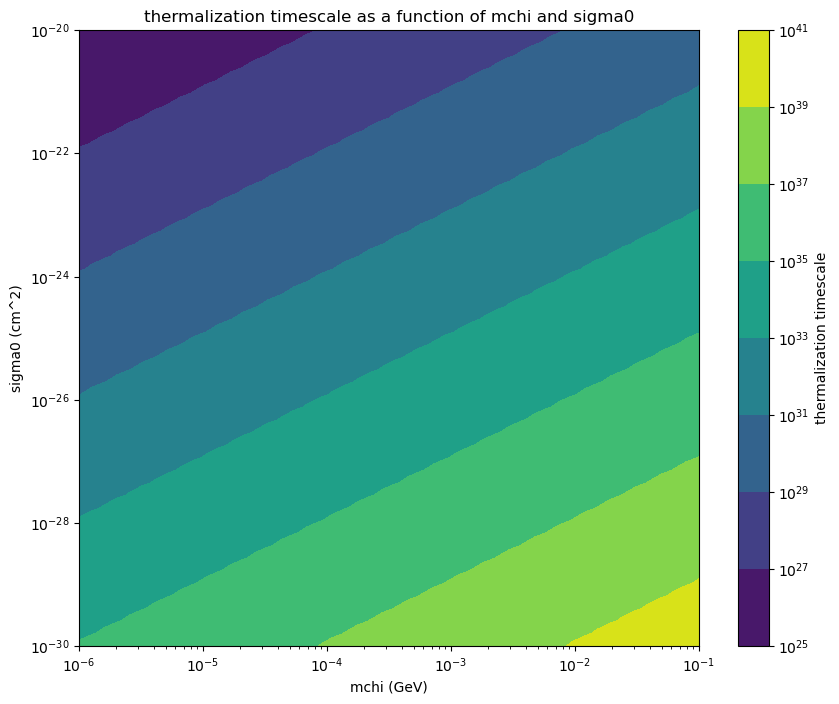

In [12]:
# Define the range of sigma0 and mchi values
sigma0_values = np.logspace(-30, -20, 50)  # Example range in cm^2
mchi_values = np.logspace(-6, -1, 50)       # Example range in GeV

# Create a meshgrid for sigma0 and mchi
sigma0_grid, mchi_grid = np.meshgrid(sigma0_values, mchi_values)

# Calculate the interaction rate for each combination of sigma0 and mchi
thermalization_grid = np.zeros_like(sigma0_grid)
for i in range(sigma0_grid.shape[0]):
    for j in range(sigma0_grid.shape[1]):
        sigma0 = sigma0_grid[i, j]
        mchi = mchi_grid[i, j]
        thermalization_grid[i, j] = test_nfw.therm.thermalization_timescale(sigma0, mchi)

# Plot the results
plt.figure(figsize=(10, 8))
cp = plt.contourf(mchi_grid, sigma0_grid, thermalization_grid, cmap='viridis', norm=LogNorm())
plt.colorbar(cp, label='thermalization timescale')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm^2)')
plt.title('thermalization timescale as a function of mchi and sigma0')
plt.show()

In [13]:
u.Mpc.to(u.cm)

3.085677581491367e+24

In [14]:
u.s.to(u.Gyr)

3.168808781402895e-17

In [15]:
(1/test_nfw.therm.calculate_interaction_rate(1e-4, 1e-27)).value

3.745891521704135e-29

In [16]:
u.s.to(u.Gyr)

3.168808781402895e-17

In [17]:
u.Gyr.to(u.s)

3.15576e+16

In [18]:
sigma0s_list = test_nfw.therm.sigma0_vs_mchi_from_interaction_rate_limit(mchi_values)

In [19]:
sigma0s_upper = [s0.value + s0.plus for s0 in sigma0s_list]

In [20]:
sigma0s_lower = [s0.value - s0.minus for s0 in sigma0s_list]

Text(0, 0.5, 'sigma0 (cm2)')

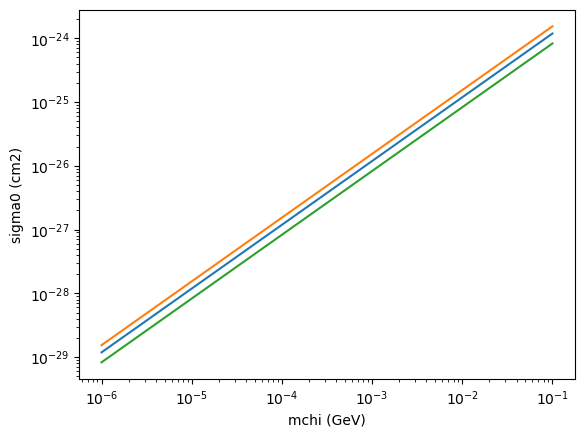

In [21]:
plt.loglog(mchi_values, sigma0s_list)
plt.loglog(mchi_values, sigma0s_upper)
plt.loglog(mchi_values, sigma0s_lower)
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm2)')
# above line does not satisfy interaction rate requirement

In [22]:
# Initialize a dictionary to store results for each mchi value
results = {mchi: [] for mchi in mchi_values}

# Iterate over each mchi value
for mchi in mchi_values:
    # For each mchi, iterate over each cluster and call the function
    for n in nfws:
        result = n.therm.sigma0_vs_mchi_from_interaction_rate_limit(mchi)
        results[mchi].append(result)

In [23]:
results

{1e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16a17b7d0>,
 1.2648552168552959e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16a182dd0>,
 1.5998587196060574e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16a9d90d0>,
 2.0235896477251557e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16aa46590>,
 2.5595479226995334e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16a9a5590>,
 3.2374575428176467e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16aa8b1d0>,
 4.094915062380427e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16aa688d0>,
 5.179474679231212e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16aa7a250>,
 6.5512855685955095e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16aa78990>,
 8.286427728546843e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16ab514d0>,
 1.0481131341546853e-05: [<asymmetric_uncertainty_mod.core.a_u at 0x16ab10050>,
 1.3257113655901109e-05: [<asymmetric_uncertainty_mod.core.a_u at 0x16ab2c850>,
 1.67683293681101e-05: [<asymmetric_uncertainty_mod.core.a_u

In [24]:
# Assuming results is a dictionary where each key is an mchi value and each value is a list of a_u objects
#results = {
    # Example structure
    # mchi_value1: [a_u_obj1, a_u_obj2, ...],
    # mchi_value2: [a_u_obj1, a_u_obj2, ...],
    # ...
#}

# Initialize dictionaries to store values and uncertainties
values_dict = {}
uncertainties_dict = {}

# Iterate over each mchi value in results
for mchi, a_u_list in results.items():
    # Initialize lists to store values and uncertainties for the current mchi
    values_list = []
    uncertainties_list = []
    
    # Iterate over each a_u object in the list
    for obj in a_u_list:
        # Extract the value and the approximate symmetric uncertainty
        value = obj.value
        uncertainty = (obj.plus + obj.minus) / 2
        
        # Append to the lists
        values_list.append(value)
        uncertainties_list.append(uncertainty)
    
    # Store the lists in the dictionaries
    values_dict[mchi] = values_list
    uncertainties_dict[mchi] = uncertainties_list

# Now values_dict contains the values and uncertainties_dict contains the uncertainties

In [25]:
values_dict

{1e-06: [1.1870013948158717e-29,
  1.1678662250084141e-29,
  1.106574540373045e-29,
  9.939773010106336e-30,
  1.434469051919916e-29,
  9.6120752597958e-30,
  1.0746682598172386e-29,
  1.18684568302705e-29,
  9.931853370674975e-30,
  1.119185744161156e-29,
  1.3208185313297526e-29,
  1.5948172275812898e-29,
  1.4191527834527325e-29,
  1.3663082597666564e-29,
  9.093071070939412e-30,
  1.2471473124551826e-29,
  1.1500091808027252e-29,
  1.282542127455888e-29,
  1.3190933911101733e-29,
  1.1079484137553937e-29,
  1.3151947046167258e-29,
  8.539298243761138e-30,
  1.0938567929200082e-29,
  1.397562513611082e-29,
  1.1909728197177382e-29,
  1.3113458653489774e-29,
  1.4128284720640242e-29,
  1.1895287500577037e-29,
  1.1943221254494953e-29,
  1.1753761713224555e-29,
  9.495607343528539e-30,
  1.3422786041938705e-29,
  1.207082933284367e-29,
  1.2671532537570836e-29,
  9.63396516978281e-30,
  9.32113591296126e-30,
  1.1404384296063286e-29,
  1.5824962659519724e-29,
  1.1368214316681107e-29,

In [26]:
uncertainties_dict

{1e-06: [3.5530193795579884e-30,
  1.906498158911807e-30,
  2.2072683183381964e-30,
  2.5539395010752206e-30,
  4.095211679688984e-30,
  2.094943039258521e-30,
  2.9009475252002477e-30,
  3.0795043732057757e-30,
  1.5141646080186483e-30,
  1.4621827026162882e-30,
  3.007358452663542e-30,
  3.6048017549584025e-30,
  5.177502156268456e-30,
  4.324167628158169e-30,
  1.719408840599652e-30,
  4.508677012732128e-30,
  3.34255634475344e-30,
  4.115797635212095e-30,
  4.660036545662071e-30,
  1.605948372456753e-30,
  3.295785997220653e-30,
  2.1352621824633867e-30,
  2.6344645028985055e-30,
  5.737183995409155e-30,
  1.868206925270657e-30,
  2.894904611726546e-30,
  3.530112804304142e-30,
  1.5105177618039851e-30,
  2.7455658169617455e-30,
  2.761434436519567e-30,
  1.577910799262074e-30,
  2.9912049141441907e-30,
  3.1294305636522764e-30,
  3.742397619044254e-30,
  2.287135174725368e-30,
  2.6897399345686905e-30,
  3.0924455274960186e-30,
  5.3209936441335615e-30,
  3.10555144763086e-30,
  3

In [27]:
results

{1e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16a17b7d0>,
 1.2648552168552959e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16a182dd0>,
 1.5998587196060574e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16a9d90d0>,
 2.0235896477251557e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16aa46590>,
 2.5595479226995334e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16a9a5590>,
 3.2374575428176467e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16aa8b1d0>,
 4.094915062380427e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16aa688d0>,
 5.179474679231212e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16aa7a250>,
 6.5512855685955095e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16aa78990>,
 8.286427728546843e-06: [<asymmetric_uncertainty_mod.core.a_u at 0x16ab514d0>,
 1.0481131341546853e-05: [<asymmetric_uncertainty_mod.core.a_u at 0x16ab10050>,
 1.3257113655901109e-05: [<asymmetric_uncertainty_mod.core.a_u at 0x16ab2c850>,
 1.67683293681101e-05: [<asymmetric_uncertainty_mod.core.a_u

In [28]:
results.items()

dict_items([(1e-06, [<asymmetric_uncertainty_mod.core.a_u object at 0x16a17b7d0>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a967150>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a236a10>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a012b50>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a2bbe90>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a9cb310>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a577950>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a2ca790>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a0ec150>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a9e3e10>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a2ac4d0>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a559850>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a91a990>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a93a690>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a664d10>, <asymmetric_uncertainty_mod.core.a_u object at 0x16a86e6d0>, <as

In [29]:
sigma0_means_list = []

# Iterate over each entry in values_dict
for mchi, values in values_dict.items():
    # Calculate the mean of the list of values
    mean_value = np.mean(values)
    
    # Append the calculated mean to means_list
    sigma0_means_list.append(mean_value)

In [30]:
# Iterate over each entry in values_dict and uncertainties_dict
s0_wmeans_list = []
for mchi in values_dict:
    values = values_dict[mchi]
    uncertainties = uncertainties_dict[mchi]
    
    # Calculate the variances (square of the uncertainties)
    variances = [uncertainty ** 2 for uncertainty in uncertainties]
    
    # Calculate the weighted mean
    weighted_mean = np.sum([value / variance for value, variance in zip(values, variances)]) / np.sum([1 / variance for variance in variances])
    
    # Append the calculated weighted mean to weighted_means_list
    s0_wmeans_list.append(weighted_mean)

In [31]:
# Initialize a list to store the weighted variances
weighted_variances_list = []

# Iterate over each entry in values_dict and uncertainties_dict
for mchi in values_dict:
    values = values_dict[mchi]
    uncertainties = uncertainties_dict[mchi]
    
    # Calculate the variances (square of the uncertainties)
    variances = [uncertainty ** 2 for uncertainty in uncertainties]
    
    # Calculate the weighted mean
    weighted_mean = np.sum([value / variance for value, variance in zip(values, variances)]) / np.sum([1 / variance for variance in variances])
    
    # Calculate the weighted variance
    weighted_variance = np.sum([(value - weighted_mean) ** 2 / variance for value, variance in zip(values, variances)]) / np.sum([1 / variance for variance in variances])
    
    # Append the calculated weighted variance to weighted_variances_list
    weighted_variances_list.append(weighted_variance)

# Now weighted_variances_list contains the weighted variances for each entry in values_dict

In [32]:
weighted_variances_list

[2.1433439171955473e-60,
 3.4290474550399017e-60,
 5.485991470888541e-60,
 8.776811290385493e-60,
 1.404165807326013e-59,
 2.2464669106232095e-59,
 3.5940296752670242e-59,
 5.749939714498873e-59,
 9.199091189450185e-59,
 1.4717246251893148e-58,
 2.3545514744680805e-58,
 3.7669497071890735e-58,
 6.0265873353639234e-58,
 9.641688297949415e-58,
 1.5425339095198045e-57,
 2.4678363254332806e-57,
 3.9481894638050043e-57,
 6.316545340325201e-57,
 1.0105580140506289e-56,
 1.6167500504466801e-56,
 2.5865716656306563e-56,
 4.13814923314517e-56,
 6.620454133678436e-56,
 1.0591791273517405e-55,
 1.6945369625184176e-55,
 2.7110197351798534e-55,
 4.3372485623515906e-55,
 6.938984931577049e-55,
 1.1101395547998576e-54,
 1.776066446726139e-54,
 2.841455391394566e-54,
 4.54592718429424e-54,
 7.272841244487351e-54,
 1.1635518481303663e-53,
 1.8615185699451082e-53,
 2.9781667158352875e-53,
 4.764645988769618e-53,
 7.622760430969096e-53,
 1.2195339742953958e-52,
 1.9510820626323196e-52,
 3.121455650569288

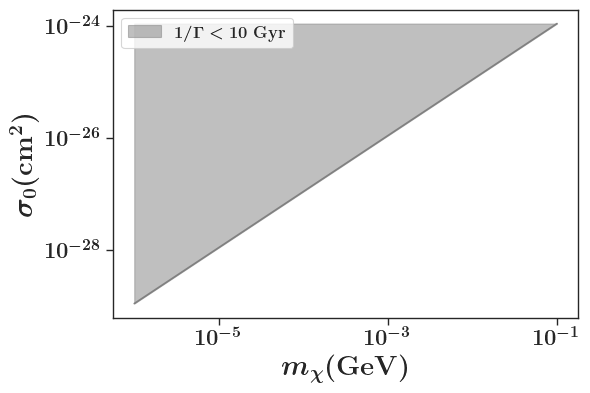

In [33]:
paper_plot()
plt.loglog(mchi_values, s0_wmeans_list, color='gray')

plt.fill_between(mchi_values, s0_wmeans_list, y2=max(s0_wmeans_list), where=(s0_wmeans_list <= max(s0_wmeans_list)), interpolate=True, color='gray', alpha=0.5, label=f'$\mathrm{{1/\Gamma < 10~Gyr}}$')
#plt.loglog(mchi_values, np.add(s0_wmeans_list,weighted_variances_list))
plt.legend()

plt.xlabel(r"$m_{\chi} \mathrm{(GeV)}$")
plt.ylabel(r"$\sigma_0 (\mathrm{cm}^2)$")
plt.savefig('plots/interaction_rate_limit.pdf')

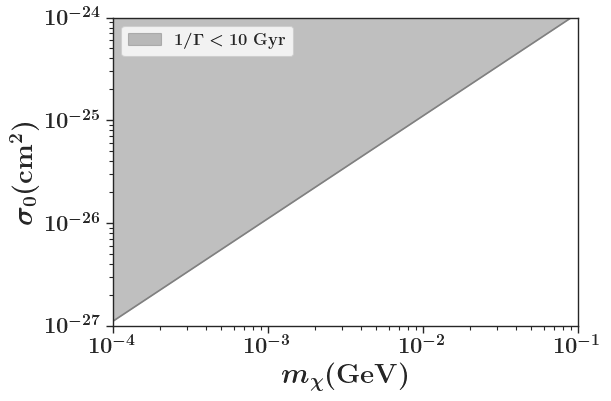

In [34]:
paper_plot()
plt.loglog(mchi_values, s0_wmeans_list, color='gray')

plt.fill_between(mchi_values, s0_wmeans_list, y2=max(s0_wmeans_list), where=(s0_wmeans_list <= max(s0_wmeans_list)), interpolate=True, color='gray', alpha=0.5, label=f'$\mathrm{{1/\Gamma < 10~Gyr}}$')
#plt.loglog(mchi_values, np.add(s0_wmeans_list,weighted_variances_list))
plt.legend()

plt.xlabel(r"$m_{\chi} \mathrm{(GeV)}$")
plt.ylabel(r"$\sigma_0 (\mathrm{cm}^2)$")
plt.xlim(1e-4,1e-1)
plt.ylim(1e-27, 1e-24)
plt.savefig('plots/interaction_rate_limit.pdf')

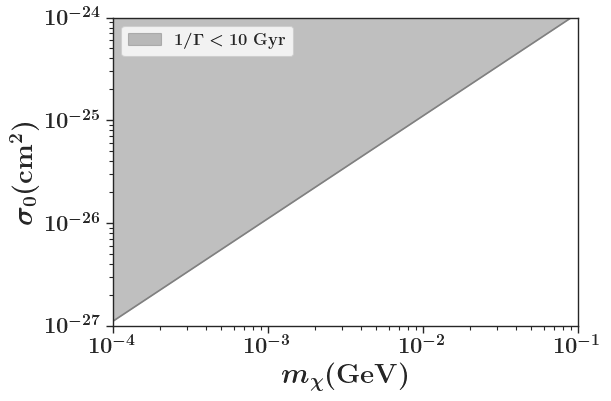

In [35]:
paper_plot()
limit = np.subtract(s0_wmeans_list,2*np.array(weighted_variances_list))
plt.loglog(mchi_values, limit, color='gray')


#plt.loglog(mchi_values, s0_wmeans_list, color='gray')

plt.fill_between(mchi_values, limit, y2=max(limit), where=(limit <= max(limit)), interpolate=True, color='gray', alpha=0.5, label=f'$\mathrm{{1/\Gamma < 10~Gyr}}$')
#plt.loglog(mchi_values, np.add(s0_wmeans_list,weighted_variances_list))
plt.legend()

plt.xlabel(r"$m_{\chi} \mathrm{(GeV)}$")
plt.ylabel(r"$\sigma_0 (\mathrm{cm}^2)$")
plt.xlim(1e-4,1e-1)
plt.ylim(1e-27, 1e-24)
plt.savefig('plots/interaction_rate_limit.pdf')

In [36]:
prior = {'mchi': mchi_values, 'max_s0': limit}

In [37]:
# Pickle the dictionary to a file
with open('data/prior_boundary_points.pkl', 'wb') as f:
    pickle.dump(prior, f)